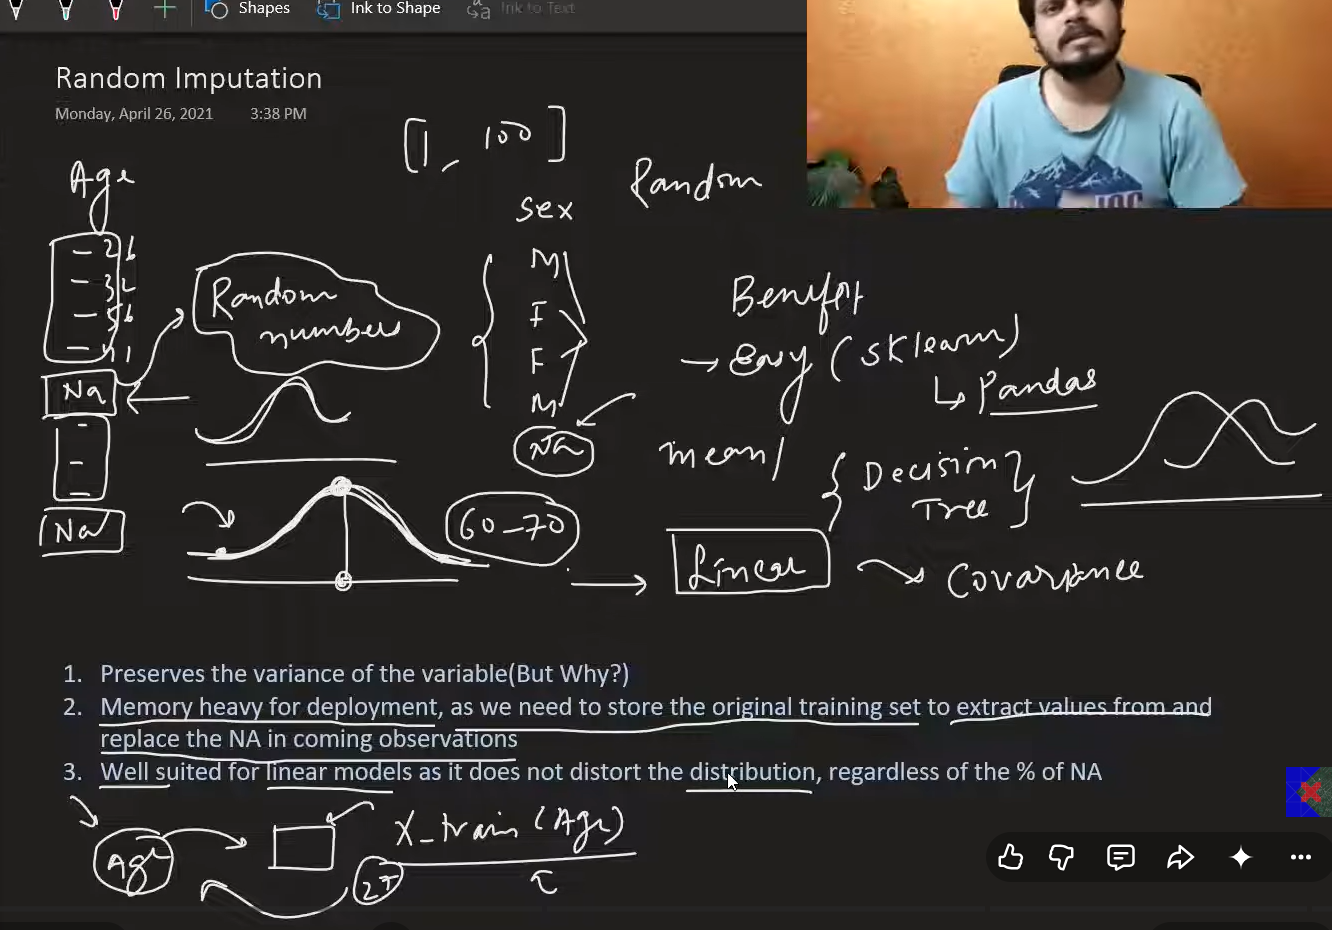

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

# Numerical Data

In [3]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [4]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [5]:
df.isnull().mean() * 100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [6]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [7]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [8]:
X_train

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458
...,...,...
534,30.0,8.6625
584,NaN,8.7125
493,71.0,49.5042
527,NaN,221.7792


In [15]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [10]:
X_test.tail()

,Age,Fare,Age_imputed
89,24.0,8.0500,24.0
80,22.0,9.0000,22.0
846,NaN,69.5500,NaN
870,26.0,7.8958,26.0
251,29.0,10.4625,29.0


In [16]:
# 'Age' se NULL values hata ke randomly values choose karke 'Age_imputed' ke NULL places me fill kar rahe hain

X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

In [22]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([ 4. , 17. , 32. , 35. , 51. , 23.5, 39. , 30.5, 25. , 15. , 30. ,
       58. , 21. , 32. , 26. , 24. , 25. , 37. , 17. , 60. , 11. , 16. ,
       21. , 21. , 27. , 14. ,  9. , 54. , 21. , 21. , 36. , 17. , 24. ,
       45. , 18. , 38. , 16. , 28. , 29. , 21. , 45. , 29. , 36. , 42. ,
       24. , 31. , 25. , 22. , 24. , 65. , 29. , 62. , 22. , 36. , 25. ,
       28. , 37. , 44. , 27. , 56. , 29. , 34. , 30. , 33. ,  3. , 19. ,
       26. , 34. , 19. , 35. , 39. , 24. , 30. , 30. , 41. , 36. , 27. ,
       31. ,  8. , 36. , 24. , 16. , 18. , 27. , 32. , 18. , 40. , 25. ,
       14. , 19. , 22. , 29. , 29. , 45. , 28. ,  3. , 70.5, 71. , 39. ,
       40. , 14. , 24. , 29. , 58. , 54. , 40. , 31. , 35. , 19. , 28.5,
       28. ,  2. , 33. , 24. , 38. , 28. , 49. , 21. , 44. , 24. , 53. ,
        5. ,  8. , 35. , 36. ,  2. , 27. , 26. , 52. , 24. , 41. , 16. ,
       24. , 37. , 39. , 27. , 40. , 26. , 19. , 14. , 29. , 40. , 16. ,
        9. , 32. , 17. , 40. , 47. ])

In [23]:
X_train['Age'].isnull().sum()

np.int64(148)

In [24]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,30.0
493,71.0,49.5042,71.0
527,NaN,221.7792,30.0


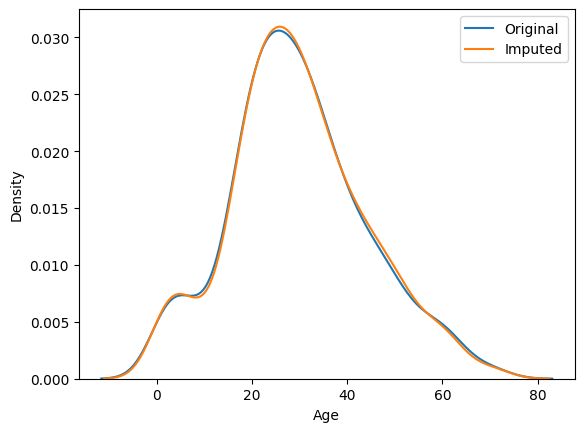

In [29]:
sns.kdeplot(X_train['Age'],label='Original')
sns.kdeplot(X_train['Age_imputed'],label = 'Imputed')

plt.legend()
plt.show()

In [30]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

Original variable variance:  204.34951339046142
Variance after random imputation:  202.41798909827904


In [31]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,59.698831
Age,71.512440,204.349513,204.349513
Age_imputed,59.698831,204.349513,202.417989


<Axes: >

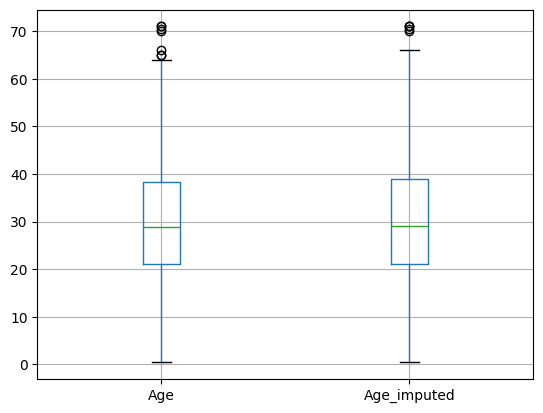

In [32]:
X_train[['Age', 'Age_imputed']].boxplot()

In [33]:
# This line implements deterministic (reproducible) random sampling using a row's own feature value as the random seed.
# In production machine learning systems, it ensures that if the same data point is sent to your model multiple times, it will always receive the exact same imputed Age and produce the exact same prediction.

sampled_value = X_train['Age'].dropna().sample(1, random_state=int(observation['Fare']))

NameError: name 'observation' is not defined

# Categorical data

In [34]:
data = pd.read_csv('house-train.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [35]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [36]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [37]:
X = data
y = data['SalePrice']

In [38]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [39]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [40]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
399,NaN,TA,241000,TA,NaN
630,NaN,Fa,124000,Fa,NaN
110,NaN,TA,136900,TA,NaN
1114,NaN,TA,117000,TA,NaN
1318,TA,TA,275000,TA,TA


In [42]:
# Impute GarageQual using .loc
X_train.loc[X_train['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = (
    X_train['GarageQual'].dropna().sample(X_train['GarageQual_imputed'].isnull().sum()).values
)
X_test.loc[X_test['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = (
    X_train['GarageQual'].dropna().sample(X_test['GarageQual_imputed'].isnull().sum()).values
)

# Impute FireplaceQu using .loc
X_train.loc[X_train['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = (
    X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu_imputed'].isnull().sum()).values
)
X_test.loc[X_test['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = (
    X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu_imputed'].isnull().sum()).values
)

In [43]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

In [44]:
temp

,original,imputed
TA,0.951043,0.952055
Fa,0.037171,0.036815
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [45]:
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.649832
TA,0.412439,0.539843
Fa,0.040917,0.052750
Po,0.027823,0.035915
Ex,0.024550,0.032548


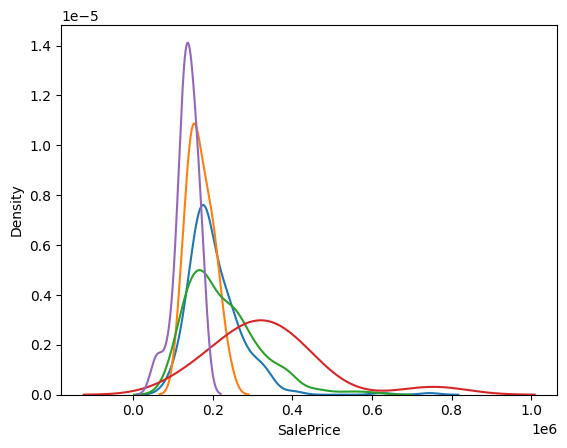

In [47]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],label=category)
plt.show()

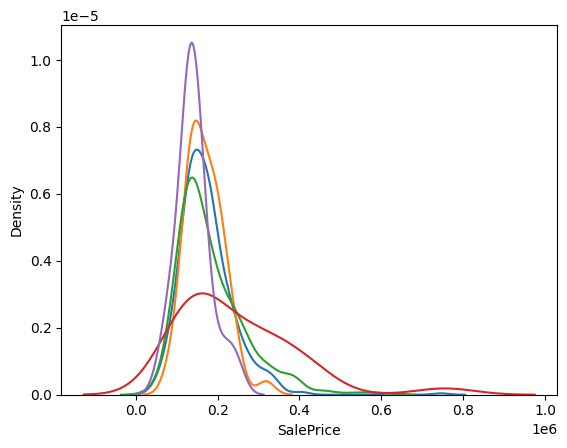

In [48]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],label=category)
plt.show()